# 03 · Probability, Statistics and Information Theory

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/03-probability-information/03_probability_information.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-03-probability-information.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 03](https://github.com/anuxlab/deep-learning-systems/wiki/Module-03) |
| **Level** | Foundational |
| **Typical CPU runtime** | < 1 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 01–02 |

## What you will do

- Apply Bayes' theorem and verify it by simulation.
- Sample common distributions and verify expectation/variance/covariance formulas.
- Derive maximum-likelihood estimates and confirm them numerically; see Monte Carlo $1/\sqrt n$ convergence.
- Compute entropy, cross-entropy, KL divergence and mutual information, and verify key identities and inequalities.
- Connect cross-entropy to negative log-likelihood and implement a numerically stable softmax loss.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

15:59:29 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43902312567
          commit: ea9ecec1804760af0b0aade14a8ad3c6e1505150


## 1 · Bayes' theorem — the base-rate trap
$$P(D\mid +)=\frac{P(+\mid D)P(D)}{P(+\mid D)P(D)+P(+\mid \neg D)P(\neg D)}.$$
A test with 99% sensitivity and 5% false-positive rate for a disease with 1% prevalence: what is $P(D\mid +)$? (Most people guess ≈ 95%.) We compute it exactly and by simulating a million people.

In [2]:
sens, fpr, prev = 0.99, 0.05, 0.01
post = sens * prev / (sens * prev + fpr * (1 - prev))
print(f"analytic P(D|+) = {post:.4f}")
rng = np.random.default_rng(0); N = 1_000_000
D = rng.random(N) < prev
pos = np.where(D, rng.random(N) < sens, rng.random(N) < fpr)
sim = D[pos].mean(); print(f"simulated P(D|+) = {sim:.4f}  (from {pos.sum():,} positives)")
check(abs(sim - post) < 0.005, "simulation agrees with Bayes' theorem")
check(post < 0.2, "posterior is far below sensitivity: base rates matter")
METRICS["posterior_disease_given_positive"] = post

analytic P(D|+) = 0.1667
simulated P(D|+) = 0.1670  (from 59,176 positives)
  ✅ simulation agrees with Bayes' theorem
  ✅ posterior is far below sensitivity: base rates matter


## 2 · PMF, PDF, CDF and common distributions
We draw samples and overlay theory: Binomial (PMF), Poisson (PMF), Normal (PDF), Exponential (PDF). A histogram of samples should match the density; the empirical CDF should match the CDF (Kolmogorov–Smirnov distance → 0).

15:59:30 | INFO | figure saved -> figures/distributions.png


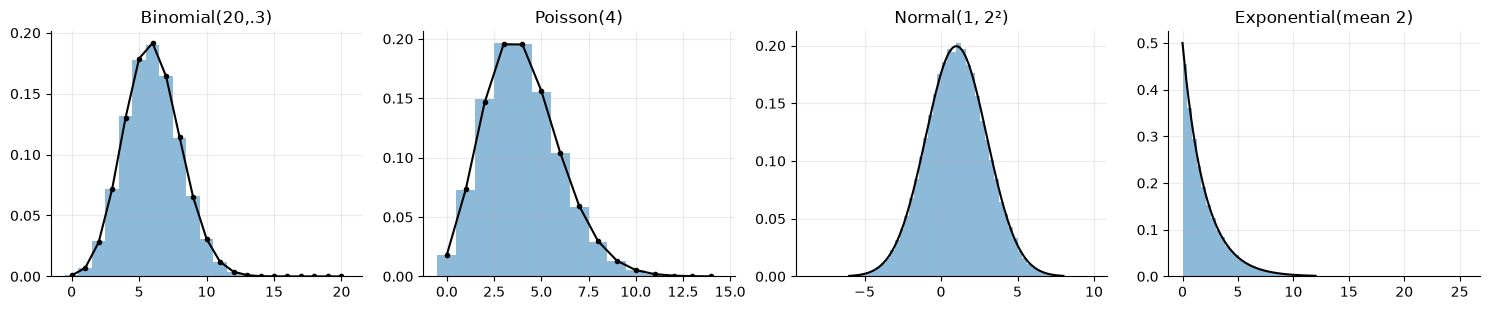

KS statistic (normal samples vs normal CDF): 0.0101  p = 0.687
  ✅ samples are consistent with the normal CDF


In [3]:
from scipy import stats
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
n = 100_000
s = stats.binom(20, .3).rvs(n, random_state=1); k = np.arange(0, 21)
ax[0].hist(s, bins=np.arange(-.5, 21), density=True, alpha=.5); ax[0].plot(k, stats.binom(20, .3).pmf(k), "ko-", ms=3); ax[0].set_title("Binomial(20,.3)")
s = stats.poisson(4).rvs(n, random_state=2); k = np.arange(0, 15)
ax[1].hist(s, bins=np.arange(-.5, 15), density=True, alpha=.5); ax[1].plot(k, stats.poisson(4).pmf(k), "ko-", ms=3); ax[1].set_title("Poisson(4)")
s = stats.norm(1, 2).rvs(n, random_state=3); x = np.linspace(-6, 8, 200)
ax[2].hist(s, bins=60, density=True, alpha=.5); ax[2].plot(x, stats.norm(1, 2).pdf(x), "k"); ax[2].set_title("Normal(1, 2²)")
s = stats.expon(scale=2).rvs(n, random_state=4); x = np.linspace(0, 12, 200)
ax[3].hist(s, bins=60, density=True, alpha=.5); ax[3].plot(x, stats.expon(scale=2).pdf(x), "k"); ax[3].set_title("Exponential(mean 2)")
show("distributions")
ks = stats.kstest(stats.norm(1, 2).rvs(5000, random_state=5), stats.norm(1, 2).cdf)
print("KS statistic (normal samples vs normal CDF):", round(ks.statistic, 4), " p =", round(ks.pvalue, 3))
check(ks.pvalue > 0.01, "samples are consistent with the normal CDF")

## 3 · Expectation, variance, covariance, independence
Linearity: $\mathbb{E}[aX+bY]=a\mathbb{E}X+b\mathbb{E}Y$ always. Variance: $\mathrm{Var}(aX+bY)=a^2\mathrm{Var}X+b^2\mathrm{Var}Y+2ab\,\mathrm{Cov}(X,Y)$. Independent ⇒ uncorrelated, **but not conversely**: take $X\sim N(0,1)$, $Y=X^2$ — perfectly dependent yet $\mathrm{Cov}=\mathbb{E}[X^3]=0$.

In [4]:
X = rng.normal(size=500_000); Y = 0.6 * X + 0.8 * rng.normal(size=X.size)
a, b = 2.0, -3.0
lhs = np.var(a * X + b * Y); rhs = a**2 * X.var() + b**2 * Y.var() + 2 * a * b * np.cov(X, Y, ddof=0)[0, 1]
print("Var(aX+bY) =", lhs, " formula =", rhs)
check(np.isclose(lhs, rhs, rtol=1e-6), "variance-of-a-sum formula")
Z = X ** 2
print("Cov(X, X²) =", np.cov(X, Z)[0, 1], "  but corr(|X|, X²) =", np.corrcoef(np.abs(X), Z)[0, 1])
check(abs(np.cov(X, Z)[0, 1]) < 0.02, "uncorrelated (cov≈0) ...")
check(np.corrcoef(np.abs(X), Z)[0, 1] > 0.9, "... yet strongly dependent: uncorrelated ≠ independent")

Var(aX+bY) = 5.809659261281396  formula = 5.8096592612813955
  ✅ variance-of-a-sum formula
Cov(X, X²) = -0.0026531308997849545   but corr(|X|, X²) = 0.9357867292199887
  ✅ uncorrelated (cov≈0) ...
  ✅ ... yet strongly dependent: uncorrelated ≠ independent


## 4 · Joint, marginal, conditional — the bivariate Gaussian
For $(X,Y)$ jointly Gaussian with correlation $\rho$ (unit variances): $Y\mid X=x\sim\mathcal N(\rho x,\,1-\rho^2)$. We check this by conditioning samples in a thin slice around $x=1$.

conditional mean 0.800 (theory 0.800),  variance 0.361 (theory 0.360)
  ✅ conditional Gaussian formulas verified


15:59:30 | INFO | figure saved -> figures/bivariate_gaussian.png


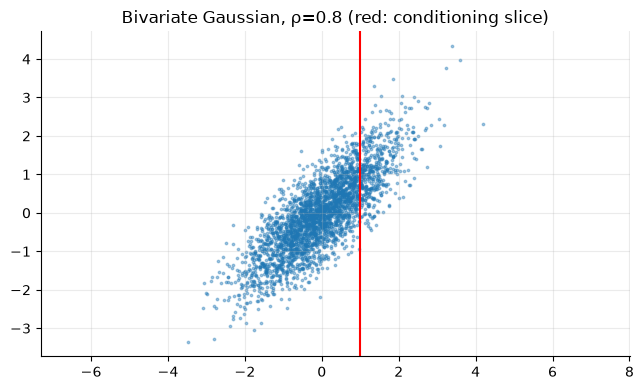

In [5]:
rho = 0.8; cov = np.array([[1, rho], [rho, 1]])
S = rng.multivariate_normal([0, 0], cov, size=2_000_000)
sl = S[np.abs(S[:, 0] - 1.0) < 0.02][:, 1]
print(f"conditional mean {sl.mean():.3f} (theory {rho*1:.3f}),  variance {sl.var():.3f} (theory {1-rho**2:.3f})")
check(abs(sl.mean() - rho) < 0.03 and abs(sl.var() - (1 - rho**2)) < 0.03, "conditional Gaussian formulas verified")
plt.scatter(*S[:3000].T, s=3, alpha=.4); plt.axvline(1, color="r"); plt.title("Bivariate Gaussian, ρ=0.8 (red: conditioning slice)"); plt.axis("equal"); show("bivariate_gaussian")

## 5 · Maximum likelihood and Monte Carlo
**MLE** maximises $\ell(\theta)=\sum_i\log p(x_i;\theta)$. For a Gaussian: $\hat\mu=\bar x$, $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$ (biased!). For Bernoulli: $\hat p=\bar x$. We also optimise the log-likelihood numerically to confirm the closed form, and show the Monte Carlo error shrinks as $1/\sqrt n$.

numerical MLE μ=2.9240 σ=1.5536 | closed form μ=2.9240 σ=1.5536
  ✅ numerical MLE == closed-form MLE


15:59:31 | INFO | figure saved -> figures/monte_carlo.png


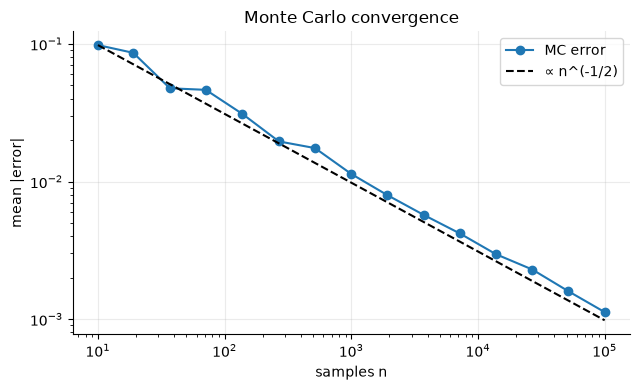

fitted slope: -0.492
  ✅ MC error decays like n^(-1/2)


In [6]:
from scipy.optimize import minimize
data = rng.normal(3.0, 1.5, size=400)
nll = lambda th: -np.sum(stats.norm(th[0], np.exp(th[1])).logpdf(data))      # parametrise log σ for positivity
res = minimize(nll, [0.0, 0.0]); mu_hat, sig_hat = res.x[0], np.exp(res.x[1])
print(f"numerical MLE μ={mu_hat:.4f} σ={sig_hat:.4f} | closed form μ={data.mean():.4f} σ={data.std():.4f}")
check(np.isclose(mu_hat, data.mean(), atol=1e-3) and np.isclose(sig_hat, data.std(), atol=1e-3), "numerical MLE == closed-form MLE")

# Monte Carlo: estimate E[cos(X)], X~N(0,1) = exp(-1/2)
true = np.exp(-0.5); ns = np.logspace(1, 5, 15).astype(int)
errs = [np.mean([abs(np.cos(rng.normal(size=n)).mean() - true) for _ in range(30)]) for n in ns]
plt.loglog(ns, errs, "o-", label="MC error"); plt.loglog(ns, errs[0] * (ns / ns[0]) ** -0.5, "k--", label="∝ n^(-1/2)")
plt.xlabel("samples n"); plt.ylabel("mean |error|"); plt.legend(); plt.title("Monte Carlo convergence"); show("monte_carlo")
slope = np.polyfit(np.log(ns), np.log(errs), 1)[0]; print("fitted slope:", round(slope, 3))
check(abs(slope + 0.5) < 0.1, "MC error decays like n^(-1/2)")

## 6 · Entropy, cross-entropy, KL and mutual information
$$H(p)=-\sum p\log p,\quad H(p,q)=-\sum p\log q,\quad D_{KL}(p\|q)=\sum p\log\tfrac pq=H(p,q)-H(p)\ge0.$$
Mutual information $I(X;Y)=D_{KL}(p_{XY}\|p_Xp_Y)=H(X)+H(Y)-H(X,Y)$. Jensen's inequality for the convex function $-\log$ proves $D_{KL}\ge0$. We verify these identities on a random joint table.

In [7]:
def H(p): p = p[p > 0]; return -(p * np.log(p)).sum()
def KL(p, q): m = p > 0; return (p[m] * np.log(p[m] / q[m])).sum()
def CE(p, q): m = p > 0; return -(p[m] * np.log(q[m])).sum()
p = rng.dirichlet(np.ones(6)); q = rng.dirichlet(np.ones(6))
print(f"H(p)={H(p):.4f} H(p,q)={CE(p,q):.4f} KL(p||q)={KL(p,q):.4f} KL(q||p)={KL(q,p):.4f}")
check(np.isclose(CE(p, q), H(p) + KL(p, q)), "H(p,q) = H(p) + KL(p||q)")
check(KL(p, q) >= 0 and KL(q, p) >= 0, "KL ≥ 0 (Gibbs' inequality)")
check(abs(KL(p, q) - KL(q, p)) > 1e-3, "KL is asymmetric")
check(np.isclose(KL(p, p), 0), "KL(p||p) = 0")
check(H(p) <= np.log(6) + 1e-12 and np.isclose(H(np.ones(6) / 6), np.log(6)), "entropy is maximised by the uniform distribution (= log n)")

J = rng.dirichlet(np.ones(12)).reshape(3, 4); px, py = J.sum(1), J.sum(0)
MI1 = KL(J.ravel(), np.outer(px, py).ravel()); MI2 = H(px) + H(py) - H(J.ravel())
check(np.isclose(MI1, MI2), "I(X;Y) = KL(p_XY || p_X p_Y) = H(X)+H(Y)-H(X,Y)")
Jind = np.outer(px, py); check(np.isclose(KL(Jind.ravel(), np.outer(px, py).ravel()), 0), "independent joint has zero mutual information")
# Gaussian closed-form KL vs Monte Carlo
m1, s1, m2, s2 = 0.0, 1.0, 1.0, 2.0
kl_cf = np.log(s2 / s1) + (s1**2 + (m1 - m2)**2) / (2 * s2**2) - 0.5
xs = rng.normal(m1, s1, 2_000_000); kl_mc = np.mean(stats.norm(m1, s1).logpdf(xs) - stats.norm(m2, s2).logpdf(xs))
print(f"Gaussian KL closed form {kl_cf:.4f} vs Monte Carlo {kl_mc:.4f}")
check(abs(kl_cf - kl_mc) < 0.01, "closed-form Gaussian KL matches Monte Carlo")

H(p)=1.5174 H(p,q)=2.2690 KL(p||q)=0.7517 KL(q||p)=0.6251
  ✅ H(p,q) = H(p) + KL(p||q)
  ✅ KL ≥ 0 (Gibbs' inequality)
  ✅ KL is asymmetric
  ✅ KL(p||p) = 0
  ✅ entropy is maximised by the uniform distribution (= log n)
  ✅ I(X;Y) = KL(p_XY || p_X p_Y) = H(X)+H(Y)-H(X,Y)
  ✅ independent joint has zero mutual information
Gaussian KL closed form 0.4431 vs Monte Carlo 0.4431
  ✅ closed-form Gaussian KL matches Monte Carlo


## 7 · Cross-entropy = negative log-likelihood, and numerical stability
For a one-hot target $y$ with predicted distribution $\hat p=\mathrm{softmax}(z)$, $H(y,\hat p)=-\log\hat p_{c}$: minimising cross-entropy **is** maximum likelihood. Computing softmax naïvely overflows; use the *log-sum-exp trick*: $\log\mathrm{softmax}(z)_i=z_i-\max z-\log\sum_j e^{z_j-\max z}$.

In [8]:
def softmax_naive(z): e = np.exp(z); return e / e.sum()
def log_softmax(z): zs = z - z.max(); return zs - np.log(np.exp(zs).sum())
z = np.array([1000., 1001., 1002.])
with np.errstate(all="ignore"):
    print("naive softmax :", softmax_naive(z))
print("stable log-softmax:", log_softmax(z))
check(np.all(np.isfinite(log_softmax(z))), "log-sum-exp trick avoids overflow")
logits = rng.normal(size=(5, 4)); y = rng.integers(0, 4, 5)
ls = np.array([log_softmax(r) for r in logits]); nll = -ls[np.arange(5), y].mean()
ce_torch = F.cross_entropy(torch.tensor(logits), torch.tensor(y)).item()
print(f"NLL (ours) {nll:.6f}  torch cross_entropy {ce_torch:.6f}")
check(np.isclose(nll, ce_torch), "cross-entropy loss == mean negative log-likelihood == torch")

naive softmax : [nan nan nan]
stable log-softmax: [-2.40760596 -1.40760596 -0.40760596]
  ✅ log-sum-exp trick avoids overflow
NLL (ours) 1.830359  torch cross_entropy 1.830359
  ✅ cross-entropy loss == mean negative log-likelihood == torch


In [9]:
save_metrics("03", METRICS)
log.info('notebook 03 finished OK')

15:59:31 | INFO | metrics saved -> metrics.json


15:59:31 | INFO | notebook 03 finished OK


## Wrap-up

## Exercises (do these next)

1. Show that MLE of the Gaussian variance with `ddof=1` is unbiased by simulation over many small samples.
2. Compute the mutual information between two pixels of a digit image (from `sklearn.datasets.load_digits`).
3. Verify numerically that $\mathrm{KL}(\mathcal N(0,1)\|\mathcal N(\mu,1))=\mu^2/2$.

## Where to read more

- Wiki chapter: [Module 03](https://github.com/anuxlab/deep-learning-systems/wiki/Module-03) (derivations, worked example, Q&A).
- Cover & Thomas, *Elements of Information Theory*.
- Murphy, *Probabilistic Machine Learning: An Introduction*.